# Project 1: Customer Segmentation using K-Means Clustering
**MCA III Semester (Session 2026-2027) - COER University, Roorkee | Lab Sheet-07**

**Problem:** A shop wants to understand its customers. Using age, annual income,
spending score and purchasing behaviour, we group similar customers into
**segments** so that the shop can plan a different marketing action for each group.

This is **unsupervised learning**: the data has no "correct answer" column.
The algorithm finds the groups on its own.

**Workflow:** load -> explore -> clean -> scale -> choose the number of clusters ->
K-Means -> visualize -> describe each segment -> compare techniques -> save -> predict.

## Step 1: Imports and settings

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
    if BASE_DIR.name == "notebooks":
        BASE_DIR = BASE_DIR.parent

DATA_PATH = BASE_DIR / "datasets" / "customer_data.csv"
MODEL_DIR = BASE_DIR / "models"
OUT_DIR = BASE_DIR / "outputs"
MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200)          # show wide tables fully
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 42
FEATURES = ["Age", "Annual_Income_k", "Spending_Score", "Purchase_Frequency",
            "Avg_Order_Value", "Days_Since_Last_Purchase"]
PLOT_X, PLOT_Y = "Annual_Income_k", "Spending_Score"   # the two columns used for 2D pictures
CHOSEN_K = None      # leave None to use the best K found in Step 7, or type your own number


def save_and_show(file_name):
    """Save the current figure into the outputs folder and display it."""
    plt.savefig(OUT_DIR / file_name, dpi=120, bbox_inches="tight")
    plt.show()


def cluster_scores(data, labels):
    """The three evaluation scores used in this project."""
    return {"Silhouette": silhouette_score(data, labels),
            "Davies-Bouldin": davies_bouldin_score(data, labels),
            "Calinski-Harabasz": calinski_harabasz_score(data, labels)}

## Step 2: Load the dataset

In [2]:
try:
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
    raw_df = pd.read_csv(DATA_PATH)
except (FileNotFoundError, pd.errors.ParserError) as err:
    print("Error while loading dataset:", err)
    raise

print("Shape:", raw_df.shape)
print(raw_df.head())

Shape: (405, 8)
   CustomerID  Gender   Age  Annual_Income_k  Spending_Score  Purchase_Frequency  Avg_Order_Value  Days_Since_Last_Purchase
0        1001    Male  40.0             22.2            21.0                 4.2              432                        37
1        1002    Male  44.0             85.5            16.0                 0.5             3031                        40
2        1003    Male  65.0             22.2            21.0                 2.6              697                        52
3        1004  Female  35.0             67.1            41.0                 3.9             1070                        37
4        1005    Male  41.0             32.1            30.0                 1.0              715                        44


## Step 3: Explore the data (EDA)

In [3]:
raw_df.info()
print("\nSummary statistics:\n", raw_df.describe().round(2))
print("\nMissing values:\n", raw_df.isnull().sum())
print("\nDuplicate rows:", raw_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 405 entries, 0 to 404
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                405 non-null    int64  
 1   Gender                    405 non-null    str    
 2   Age                       395 non-null    float64
 3   Annual_Income_k           399 non-null    float64
 4   Spending_Score            400 non-null    float64
 5   Purchase_Frequency        398 non-null    float64
 6   Avg_Order_Value           405 non-null    int64  
 7   Days_Since_Last_Purchase  405 non-null    int64  
dtypes: float64(4), int64(3), str(1)
memory usage: 27.4 KB

Summary statistics:
        CustomerID     Age  Annual_Income_k  Spending_Score  Purchase_Frequency  Avg_Order_Value  Days_Since_Last_Purchase
count      405.00  395.00           399.00          400.00              398.00           405.00                    405.00
mean      1199.41   37.89       

## Step 4: Clean the data
1. Remove duplicate rows.
2. Fill missing numbers with the **median** (it is not pulled by extreme values).
3. Find **outliers** with the IQR rule and **cap** them at the limit.
   Capping keeps the customer but stops one extreme value from dragging a cluster centre.

In [4]:
clean_df = raw_df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(clean_df))

for column in FEATURES:
    clean_df[column] = clean_df[column].fillna(clean_df[column].median())
print("Missing values left:", int(clean_df[FEATURES].isnull().sum().sum()))

outlier_report = []
for column in FEATURES:
    q1, q3 = clean_df[column].quantile(0.25), clean_df[column].quantile(0.75)
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    count = int(((clean_df[column] < low) | (clean_df[column] > high)).sum())
    if count:
        outlier_report.append((column, count, round(float(low), 1), round(float(high), 1)))
        clean_df[column] = clean_df[column].clip(low, high)
print("\nOutliers capped (column, count, lower limit, upper limit):")
for row in outlier_report:
    print("  ", row)

Rows after removing duplicates: 400
Missing values left: 0

Outliers capped (column, count, lower limit, upper limit):
   ('Annual_Income_k', 3, -28.6, 146.0)
   ('Avg_Order_Value', 4, -1381.5, 4604.5)
   ('Days_Since_Last_Purchase', 2, -21.5, 62.5)


## Step 5: Visualize the data before clustering

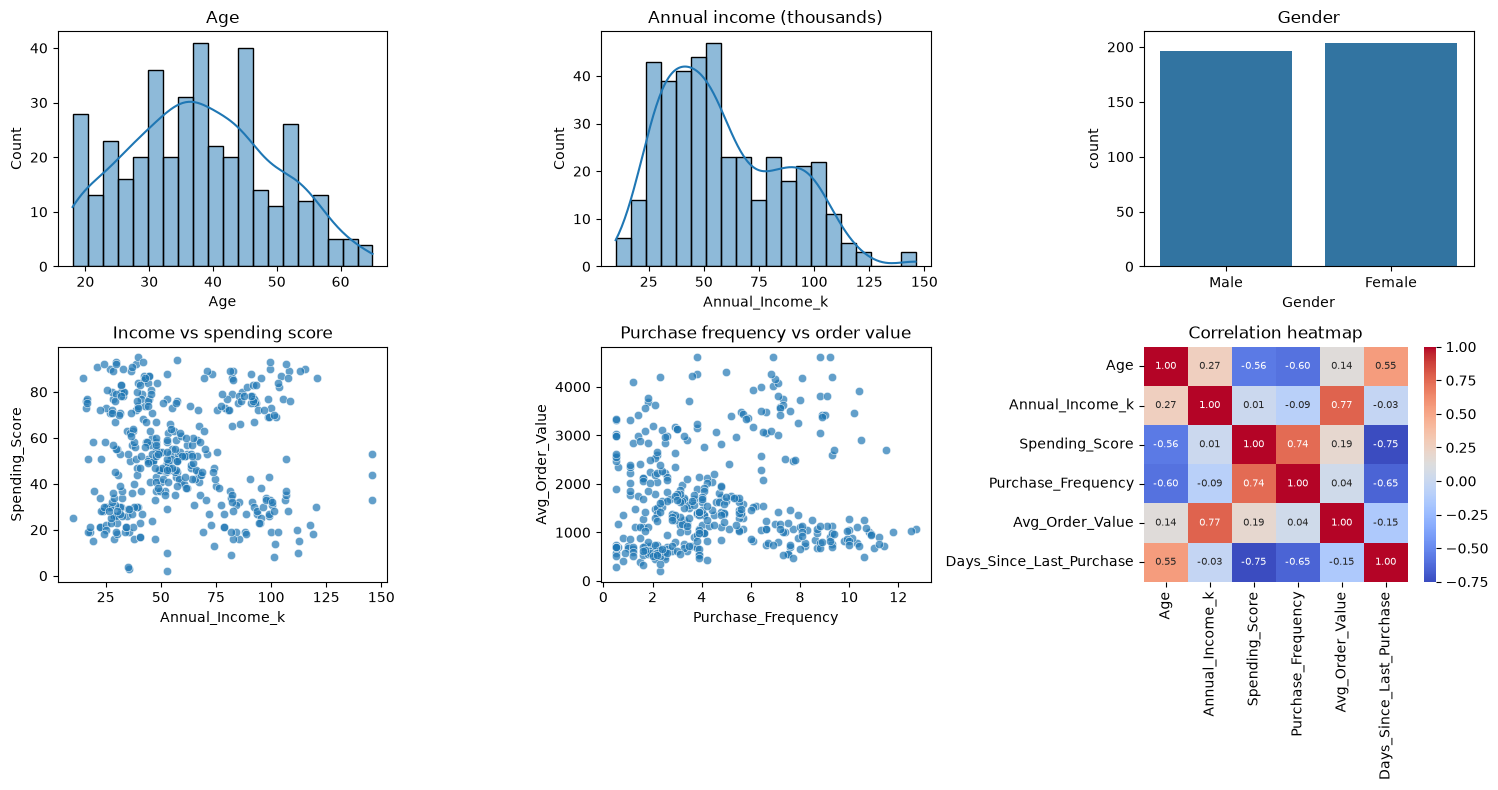

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(clean_df["Age"], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age")
sns.histplot(clean_df["Annual_Income_k"], bins=20, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Annual income (thousands)")
sns.countplot(x="Gender", data=clean_df, ax=axes[0, 2])
axes[0, 2].set_title("Gender")
sns.scatterplot(x=PLOT_X, y=PLOT_Y, data=clean_df, ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_title("Income vs spending score")
sns.scatterplot(x="Purchase_Frequency", y="Avg_Order_Value", data=clean_df, ax=axes[1, 1], alpha=0.7)
axes[1, 1].set_title("Purchase frequency vs order value")
sns.heatmap(clean_df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            ax=axes[1, 2], annot_kws={"size": 7})
axes[1, 2].set_title("Correlation heatmap")
plt.tight_layout()
save_and_show("p1_eda.png")

## Step 6: Feature scaling
K-Means uses **distance**. Avg_Order_Value is in thousands and Purchase_Frequency is
a single digit, so without scaling the big numbers would decide the clusters alone.
`StandardScaler` gives every feature a mean of 0 and a standard deviation of 1.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clean_df[FEATURES])
print(pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(3))

        Age  Annual_Income_k  Spending_Score  Purchase_Frequency  Avg_Order_Value  Days_Since_Last_Purchase
mean -0.000            0.000          -0.000               0.000            0.000                     0.000
std   1.001            1.001           1.001               1.001            1.001                     1.001


## Step 7: Find the best number of clusters (K)
We try K = 2 to 10 and look at four things:
- **Elbow method (inertia):** the total distance of points to their cluster centre. Look for the bend.
- **Silhouette score:** how well separated the clusters are. Higher is better (maximum 1).
- **Davies-Bouldin:** lower is better.
- **Calinski-Harabasz:** higher is better.

     Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz
K                                                          
2   1525.789       0.314           1.266            228.037
3   1148.059       0.357           0.907            216.461
4    849.092       0.384           0.975            241.105
5    627.138       0.407           0.936            279.157
6    575.954       0.340           1.132            249.560
7    538.168       0.326           1.192            226.602
8    507.714       0.306           1.352            208.716
9    490.375       0.251           1.459            190.330
10   473.871       0.240           1.606            176.136

Elbow method suggests K = 5
Best silhouette score at K = 5


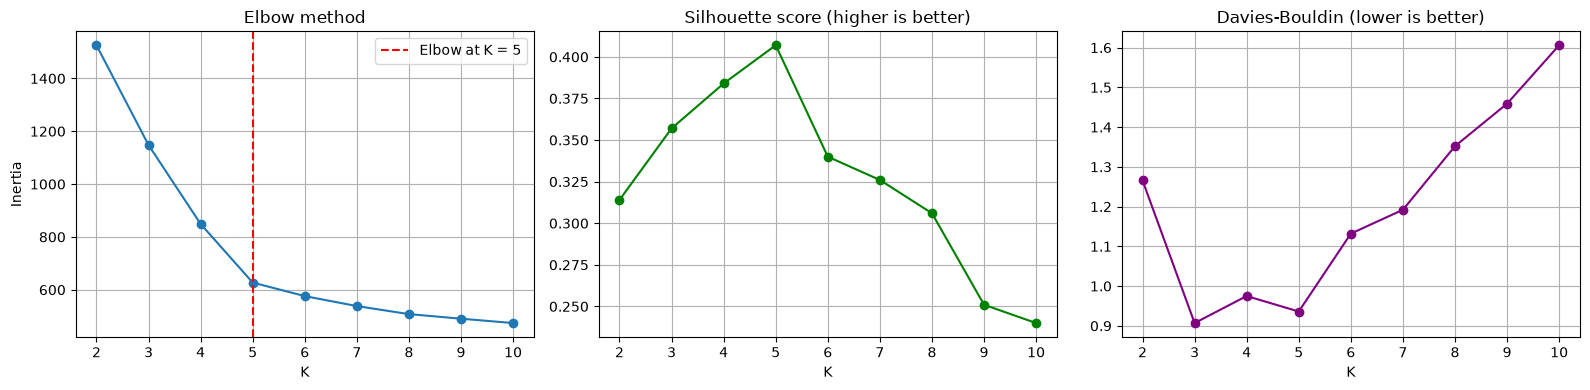


K used for the final model: 5


In [7]:
k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    scores = cluster_scores(X_scaled, model.labels_)
    k_rows.append({"K": k, "Inertia": model.inertia_, **scores})
k_table = pd.DataFrame(k_rows).set_index("K").round(3)
print(k_table)

# Find the elbow: the point farthest from the straight line joining the first and last points
k_values = k_table.index.to_numpy(dtype=float)
inertias = k_table["Inertia"].to_numpy()
start, end = np.array([k_values[0], inertias[0]]), np.array([k_values[-1], inertias[-1]])
direction = (end - start) / np.linalg.norm(end - start)
points = np.column_stack([k_values, inertias]) - start
elbow_k = int(k_values[np.abs(points[:, 0] * direction[1] - points[:, 1] * direction[0]).argmax()])
best_silhouette_k = int(k_table["Silhouette"].idxmax())
print(f"\nElbow method suggests K = {elbow_k}")
print(f"Best silhouette score at K = {best_silhouette_k}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_table.index, k_table["Inertia"], marker="o")
axes[0].axvline(elbow_k, color="red", linestyle="--", label=f"Elbow at K = {elbow_k}")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[0].legend()
axes[1].plot(k_table.index, k_table["Silhouette"], marker="o", color="green")
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("K")
axes[2].plot(k_table.index, k_table["Davies-Bouldin"], marker="o", color="purple")
axes[2].set_title("Davies-Bouldin (lower is better)")
axes[2].set_xlabel("K")
for axis in axes:
    axis.grid(True)
plt.tight_layout()
save_and_show("p1_choose_k.png")

FINAL_K = CHOSEN_K if CHOSEN_K else best_silhouette_k
print("\nK used for the final model:", FINAL_K)

## Step 8: Build the final K-Means model

In [8]:
kmeans = KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
labels = kmeans.labels_
segmented_df = clean_df.copy()
segmented_df["Cluster"] = labels
print("Customers in each cluster:")
print(segmented_df["Cluster"].value_counts().sort_index())
print("\nEvaluation scores:")
print(pd.Series(cluster_scores(X_scaled, labels)).round(4))

Customers in each cluster:
Cluster
0     80
1    131
2     67
3     61
4     61
Name: count, dtype: int64

Evaluation scores:
Silhouette             0.4065
Davies-Bouldin         0.9358
Calinski-Harabasz    279.1574
dtype: float64


**How to read the scores:** Silhouette close to 1 means customers are close to their own
cluster and far from others. Davies-Bouldin close to 0 means compact, well separated clusters.

## Step 9: Visualize the clusters

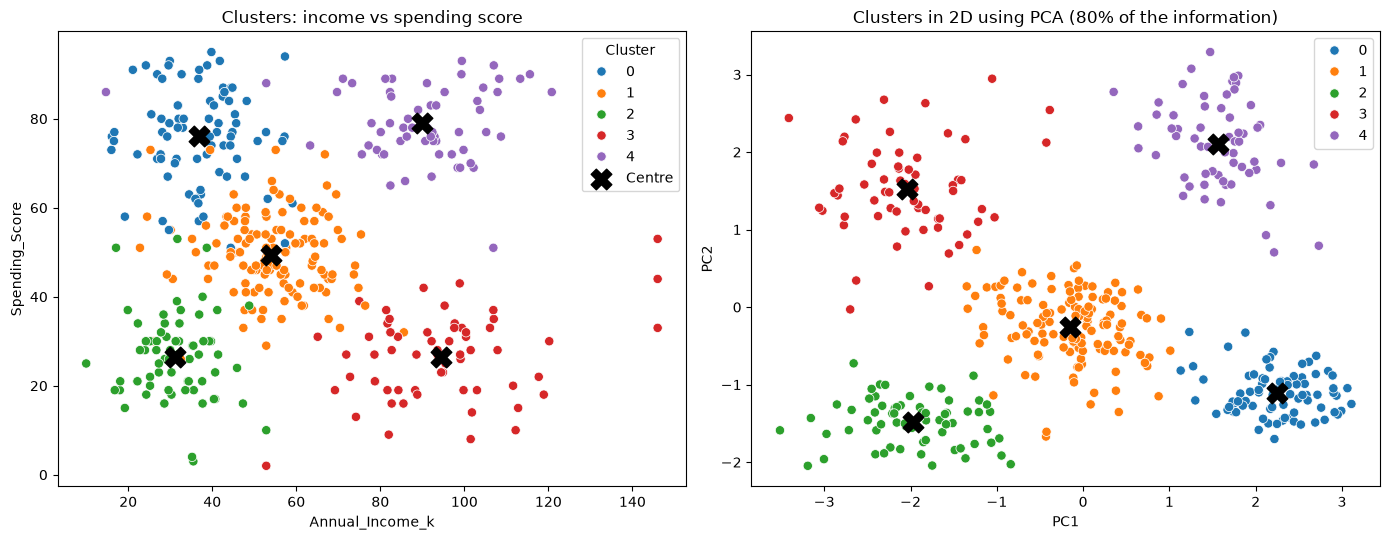

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=FEATURES)
centers_pca = pca.transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=segmented_df[PLOT_X], y=segmented_df[PLOT_Y], hue=segmented_df["Cluster"],
                palette="tab10", s=45, ax=axes[0])
axes[0].scatter(centers_df[PLOT_X], centers_df[PLOT_Y], c="black", marker="X", s=220, label="Centre")
axes[0].set_title("Clusters: income vs spending score")
axes[0].legend(title="Cluster")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="tab10", s=45, ax=axes[1])
axes[1].scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=220)
axes[1].set_title(f"Clusters in 2D using PCA ({pca.explained_variance_ratio_.sum():.0%} of the information)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
plt.tight_layout()
save_and_show("p1_clusters.png")

## Step 10: Understand each segment (business insight)
We look at the average of every feature in each cluster, and give each segment a name.

In [10]:
profile = segmented_df.groupby("Cluster")[FEATURES].mean().round(1)
profile["Customers"] = segmented_df["Cluster"].value_counts().sort_index()
profile["Share %"] = (profile["Customers"] / len(segmented_df) * 100).round(1)
print(profile)


def level(value, overall_mean):
    """Turn a number into High / Medium / Low compared with the overall average."""
    if value > overall_mean * 1.15:
        return "High"
    if value < overall_mean * 0.85:
        return "Low"
    return "Medium"


actions = {
    ("High", "High"): "Premium loyalty programme, early access to new products, personal service.",
    ("High", "Low"): "Personalised offers and product recommendations to raise their spending.",
    ("Low", "High"): "Discount bundles, student and youth offers. Keep them engaged.",
    ("Low", "Low"): "Low-cost promotions. Do not over-invest.",
}
segment_names, segment_actions = {}, {}
overall = segmented_df[FEATURES].mean()
for cluster_id, row in profile.iterrows():
    income_level = level(row["Annual_Income_k"], overall["Annual_Income_k"])
    spending_level = level(row["Spending_Score"], overall["Spending_Score"])
    segment_names[int(cluster_id)] = f"{income_level} income, {spending_level} spending"
    segment_actions[int(cluster_id)] = actions.get(
        (income_level, spending_level), "General campaigns and seasonal offers.")

print("\nSegments and suggested marketing actions:")
for cluster_id in sorted(segment_names):
    print(f"  Cluster {cluster_id}: {segment_names[cluster_id]} "
          f"({int(profile.loc[cluster_id, 'Customers'])} customers)")
    print(f"      Action: {segment_actions[cluster_id]}")
segmented_df["Segment"] = segmented_df["Cluster"].map(segment_names)

          Age  Annual_Income_k  Spending_Score  Purchase_Frequency  Avg_Order_Value  Days_Since_Last_Purchase  Customers  Share %
Cluster                                                                                                                          
0        23.9             36.9            76.2                 8.4            932.9                       8.5         80     20.0
1        38.1             54.1            49.5                 3.8           1460.0                      19.6        131     32.8
2        46.2             31.2            26.4                 2.1            618.9                      39.9         67     16.8
3        48.6             94.6            26.5                 1.9           2675.1                      36.2         61     15.2
4        35.5             90.0            79.0                 6.9           3473.9                       8.6         61     15.2

Segments and suggested marketing actions:
  Cluster 0: Low income, High spending (80 cust

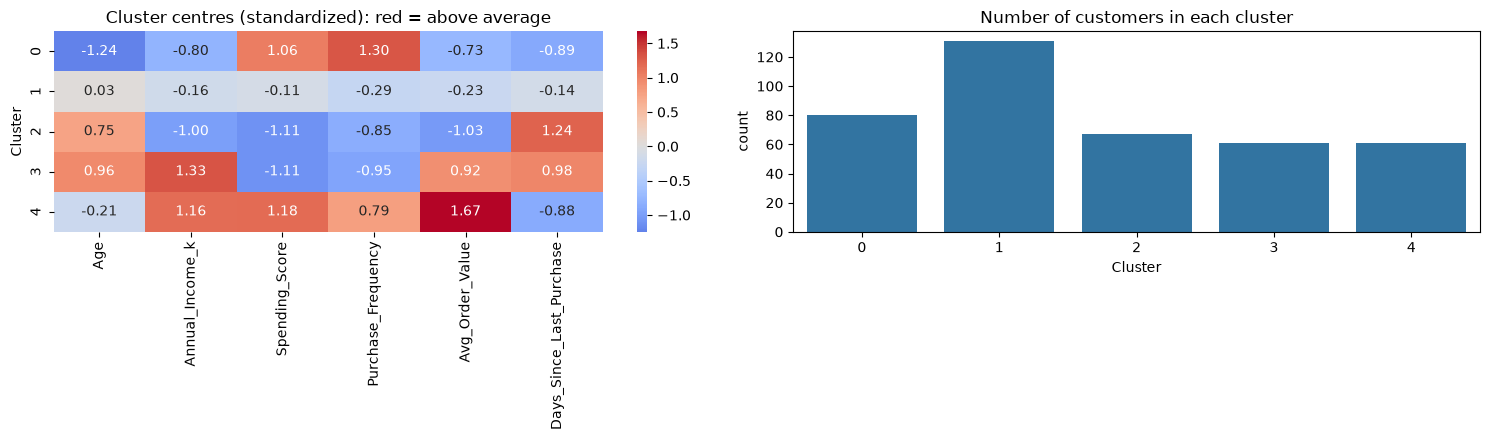

In [11]:
# Heatmap of the cluster centres in standardized units: red = above average, blue = below average
centre_z = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(centre_z, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Cluster centres (standardized): red = above average")
axes[0].set_ylabel("Cluster")
sns.countplot(x="Cluster", data=segmented_df, ax=axes[1])
axes[1].set_title("Number of customers in each cluster")
plt.tight_layout()
save_and_show("p1_segment_profiles.png")

## Step 11: Compare clustering techniques
We cluster the same scaled data with K-Means, Hierarchical (Ward) and a Gaussian Mixture,
using the same number of clusters. **Adjusted Rand Index (ARI)** shows how much a method
agrees with K-Means (1 = same groups).

In [12]:
methods = {
    "K-Means": labels,
    "Hierarchical (Ward)": AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward").fit_predict(X_scaled),
    "Hierarchical (Complete)": AgglomerativeClustering(n_clusters=FINAL_K, linkage="complete").fit_predict(X_scaled),
    "Gaussian Mixture": GaussianMixture(n_components=FINAL_K, random_state=RANDOM_STATE, n_init=3).fit_predict(X_scaled),
}
comparison_rows = []
for name, method_labels in methods.items():
    comparison_rows.append({"Method": name, **cluster_scores(X_scaled, method_labels),
                            "ARI vs K-Means": adjusted_rand_score(labels, method_labels),
                            "Smallest cluster": int(np.bincount(method_labels).min())})
comparison_table = pd.DataFrame(comparison_rows).set_index("Method").round(4)
print(comparison_table)
print("\nBest silhouette:", comparison_table["Silhouette"].idxmax())

                         Silhouette  Davies-Bouldin  Calinski-Harabasz  ARI vs K-Means  Smallest cluster
Method                                                                                                  
K-Means                      0.4065          0.9358           279.1574          1.0000                61
Hierarchical (Ward)          0.4024          0.9447           273.0629          0.9276                60
Hierarchical (Complete)      0.4036          0.9413           274.7858          0.9345                61
Gaussian Mixture             0.3995          0.9461           272.0546          0.9275                61

Best silhouette: K-Means


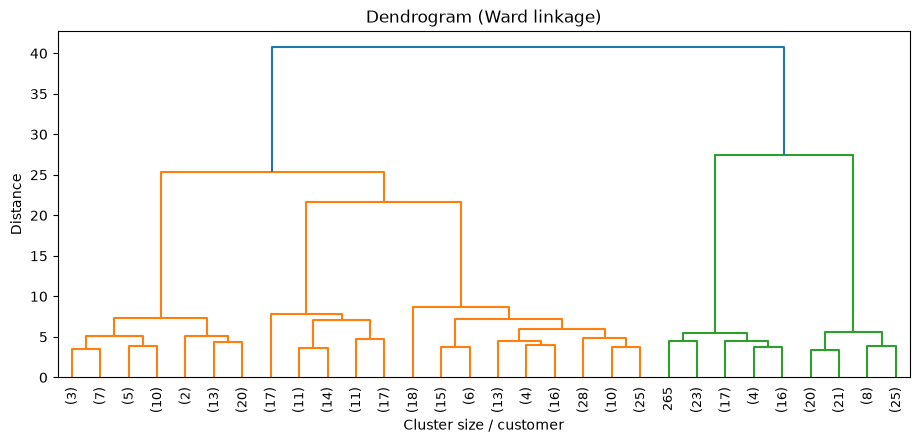

In [13]:
# Dendrogram of the hierarchical clustering (the last 30 merges)
plt.figure(figsize=(11, 4.5))
dendrogram(linkage(X_scaled, method="ward"), truncate_mode="lastp", p=30,
           leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Cluster size / customer")
plt.ylabel("Distance")
save_and_show("p1_dendrogram.png")

## Step 12: Check the result (scaling and stability)
- **Without scaling**, the large Avg_Order_Value column would dominate.
- **Stability:** a good result stays the same when K-Means starts from different random points.

In [14]:
unscaled_labels = KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE).fit_predict(
    clean_df[FEATURES].to_numpy())
print(f"Silhouette (measured on scaled data): with scaling = "
      f"{silhouette_score(X_scaled, labels):.3f}, without scaling = {silhouette_score(X_scaled, unscaled_labels):.3f}")
print(f"Agreement of both results (ARI): {adjusted_rand_score(labels, unscaled_labels):.3f}")

stability = [adjusted_rand_score(labels, KMeans(n_clusters=FINAL_K, n_init=1, random_state=seed).fit_predict(X_scaled))
             for seed in range(10)]
print(f"\nStability over 10 random starts: average ARI = {np.mean(stability):.3f}, worst = {np.min(stability):.3f}")

Silhouette (measured on scaled data): with scaling = 0.407, without scaling = 0.046
Agreement of both results (ARI): 0.435

Stability over 10 random starts: average ARI = 0.995, worst = 0.992


## Step 13: Save the model and the segmented customers

In [15]:
try:
    bundle = {"scaler": scaler, "kmeans": kmeans, "features": FEATURES,
              "segment_names": segment_names, "segment_actions": segment_actions,
              "fill_values": clean_df[FEATURES].median().to_dict()}
    joblib.dump(bundle, MODEL_DIR / "customer_segmentation_model.joblib")
    segmented_df.to_csv(OUT_DIR / "customers_segmented.csv", index=False)
    print("Saved model :", MODEL_DIR / "customer_segmentation_model.joblib")
    print("Saved data  :", OUT_DIR / "customers_segmented.csv")
except OSError as err:
    print("Could not save files:", err)

Saved model : c:\Users\rajen\OneDrive\Desktop\ml lab\LAB 07\project1_customer_segmentation\models\customer_segmentation_model.joblib
Saved data  : c:\Users\rajen\OneDrive\Desktop\ml lab\LAB 07\project1_customer_segmentation\outputs\customers_segmented.csv


## Step 14: Load the saved model and place new customers into segments

In [16]:
bundle = joblib.load(MODEL_DIR / "customer_segmentation_model.joblib")
new_customers = pd.DataFrame({
    "Age": [23, 47, 36],
    "Annual_Income_k": [38, 95, 60],
    "Spending_Score": [82, 20, 52],
    "Purchase_Frequency": [9, 2, 4],
    "Avg_Order_Value": [950, 3000, 1600],
    "Days_Since_Last_Purchase": [6, 40, 18],
})
new_clusters = bundle["kmeans"].predict(bundle["scaler"].transform(new_customers[bundle["features"]]))
result = new_customers.copy()
result["Cluster"] = new_clusters
result["Segment"] = [bundle["segment_names"][int(c)] for c in new_clusters]
print(result.to_string(index=False))

 Age  Annual_Income_k  Spending_Score  Purchase_Frequency  Avg_Order_Value  Days_Since_Last_Purchase  Cluster                        Segment
  23               38              82                   9              950                         6        0      Low income, High spending
  47               95              20                   2             3000                        40        3      High income, Low spending
  36               60              52                   4             1600                        18        1 Medium income, Medium spending


## Conclusion
The customers were cleaned, scaled and grouped with K-Means. The best number of
clusters was found with the elbow method and the silhouette score. Each segment was
described with its average values and a suggested marketing action, the result was
compared with other clustering methods, and the model was saved for new customers.